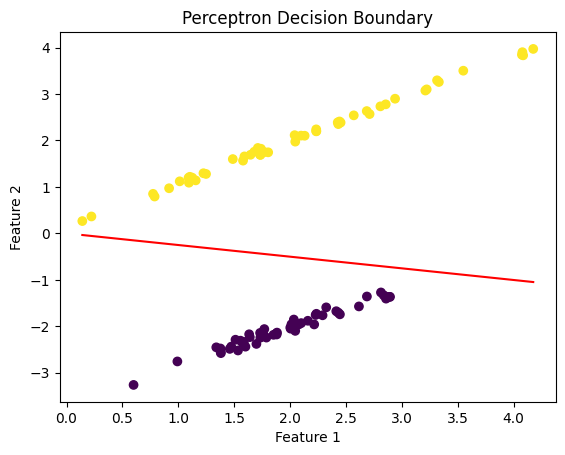

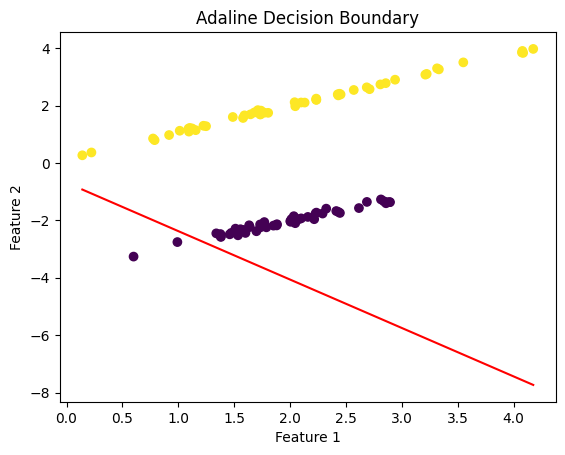

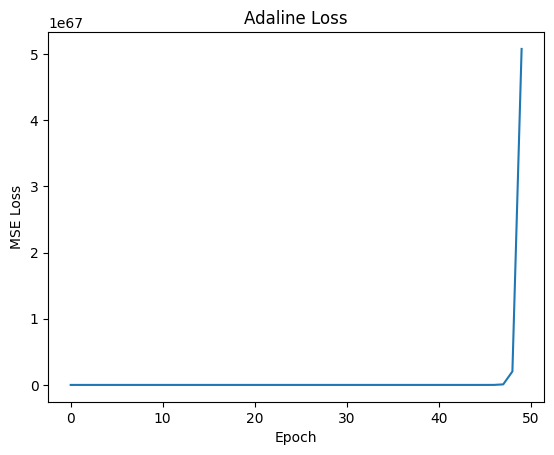

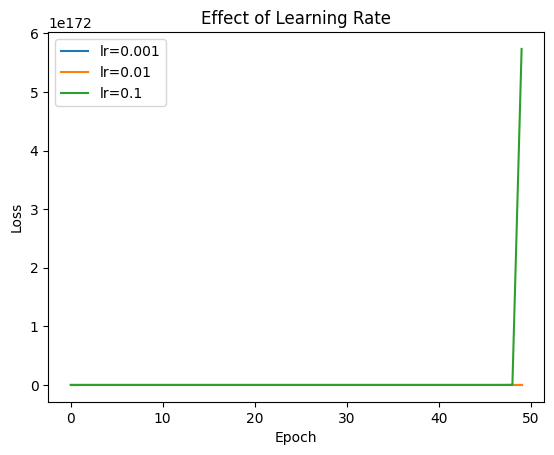

Perceptron Margin: 0.29173157554925405
Perceptron Accuracy: 1.0
Adaline Margin: -5.966745107377938
Adaline Accuracy: 0.48


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

# Generate data with labels -1 and +1
X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=2,
    random_state=42
)

y = np.where(y == 0, -1, 1)


class Perceptron:

    def __init__(self, lr=0.01, epochs=50):
        self.lr, self.epochs = lr, epochs

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0

        for _ in range(self.epochs):
            for xi, yi in zip(X, y):

                if yi * (xi @ self.w + self.b) <= 0:
                    self.w += self.lr * yi * xi
                    self.b += self.lr * yi

    def predict(self, X):
        return np.sign(X @ self.w + self.b)


class Adaline:

    def __init__(self, lr=0.01, epochs=50):
        self.lr, self.epochs = lr, epochs

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0
        self.losses = []

        for _ in range(self.epochs):
            error = y - (X @ self.w + self.b)

            self.w += self.lr * (X.T @ error)
            self.b += self.lr * error.sum()

            self.losses.append(np.mean(error**2))

    def predict(self, X):
        return np.sign(X @ self.w + self.b)


def plot_boundary(model, title):
    x = np.linspace(
        X[:, 0].min(),
        X[:, 0].max(),
        100
    )

    y_line = -(model.w[0] * x + model.b) / model.w[1]

    plt.scatter(X[:, 0], X[:, 1], c=y)
    plt.plot(x, y_line, "r")

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()


# Train both models
perceptron = Perceptron()
perceptron.fit(X, y)

adaline = Adaline()
adaline.fit(X, y)

plot_boundary(
    perceptron,
    "Perceptron Decision Boundary"
)

plot_boundary(
    adaline,
    "Adaline Decision Boundary"
)

# Plot Adaline loss
plt.plot(adaline.losses)
plt.title("Adaline Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.show()

# Compare learning rates
for lr in [0.001, 0.01, 0.1]:
    model = Adaline(lr=lr)
    model.fit(X, y)

    plt.plot(model.losses, label=f"lr={lr}")

plt.title("Effect of Learning Rate")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Print margins and accuracy
for name, model in [
    ("Perceptron", perceptron),
    ("Adaline", adaline)
]:
    margin = np.min(
        y * (X @ model.w + model.b) /
        np.linalg.norm(model.w)
    )

    accuracy = np.mean(model.predict(X) == y)

    print(f"{name} Margin:", margin)
    print(f"{name} Accuracy:", accuracy)